In [2]:
import sys
from pathlib import Path

# Add project root to sys.path so "from src..." imports work from inside notebooks/
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print("Project root added to path:", project_root)

Project root added to path: c:\Users\Anusha\HealthAudit-AI


In [3]:
import pandas as pd
from src.config.paths import MERGED_DATASET_FILE

df = pd.read_parquet(MERGED_DATASET_FILE)
df.shape

(116352, 43)

In [4]:
# Missingness summary: count and percentage per column, sorted worst first
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("missing_count", ascending=False)

# Only show columns that actually have missing values
missing_summary[missing_summary["missing_count"] > 0]

,missing_count,missing_pct
BENE_DEATH_DT,114538,98.44
avg_inpatient_payment_amt,78572,67.53
avg_outpatient_payment_amt,31080,26.71


In [5]:
# We expect avg_inpatient_payment_amt to be missing EXACTLY for beneficiaries
# with total_inpatient_claims == 0 (since "average of zero claims" is undefined).
expected_missing_inpatient = (df["total_inpatient_claims"] == 0).sum()
actual_missing_inpatient = df["avg_inpatient_payment_amt"].isna().sum()

print("Expected missing (zero inpatient claims):", expected_missing_inpatient)
print("Actual missing in avg_inpatient_payment_amt:", actual_missing_inpatient)
print("Match:", expected_missing_inpatient == actual_missing_inpatient)

# Same check for outpatient
expected_missing_outpatient = (df["total_outpatient_claims"] == 0).sum()
actual_missing_outpatient = df["avg_outpatient_payment_amt"].isna().sum()

print("\nExpected missing (zero outpatient claims):", expected_missing_outpatient)
print("Actual missing in avg_outpatient_payment_amt:", actual_missing_outpatient)
print("Match:", expected_missing_outpatient == actual_missing_outpatient)

Expected missing (zero inpatient claims): 78572
Actual missing in avg_inpatient_payment_amt: 78572
Match: True

Expected missing (zero outpatient claims): 31080
Actual missing in avg_outpatient_payment_amt: 31080
Match: True


In [6]:
financial_cols = [
    "total_inpatient_payment_amt",
    "total_outpatient_payment_amt",
    "total_inpatient_primary_payer_amt",
    "total_outpatient_primary_payer_amt",
]

df[financial_cols].describe()

,total_inpatient_payment_amt,total_outpatient_payment_amt,total_inpatient_primary_payer_amt,total_outpatient_primary_payer_amt
count,116352.000000,116352.000000,116352.000000,116352.000000
mean,5494.191591,1929.702197,228.923439,69.594850
std,13020.714133,5271.425579,2801.641739,618.178186
min,-3000.000000,-100.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,560.000000,0.000000,0.000000
75%,5000.000000,2240.000000,0.000000,0.000000
max,209000.000000,133380.000000,91000.000000,19000.000000


In [8]:
neg_inpatient = df[df["total_inpatient_payment_amt"] < 0]
neg_outpatient = df[df["total_outpatient_payment_amt"] < 0]

print("Rows with negative total_inpatient_payment_amt:", len(neg_inpatient))
print("Rows with negative total_outpatient_payment_amt:", len(neg_outpatient))

print("\n--- Sample negative inpatient rows ---")
print(neg_inpatient[["DESYNPUF_ID", "total_inpatient_claims", "total_inpatient_payment_amt", "avg_inpatient_payment_amt"]].head(10))

print("\n--- Sample negative outpatient rows ---")
print(neg_outpatient[["DESYNPUF_ID", "total_outpatient_claims", "total_outpatient_payment_amt", "avg_outpatient_payment_amt"]].head(10))

Rows with negative total_inpatient_payment_amt: 21
Rows with negative total_outpatient_payment_amt: 48

--- Sample negative inpatient rows ---
            DESYNPUF_ID  total_inpatient_claims  total_inpatient_payment_amt  \
4057   08B6E69DF1A8719A                     1.0                      -2000.0   
6196   0D50A99E345BD92E                     1.0                        -30.0   
6784   0EA1D666FE43AA90                     1.0                       -300.0   
10984  17B7E6542074F88D                     1.0                       -100.0   
20320  2C0D640D67755681                     1.0                        -20.0   
24757  3616E0473E7F742D                     1.0                      -3000.0   
30997  43BC6F6CFB59357A                     1.0                       -200.0   
34409  4B13FC5160B43311                     1.0                      -1000.0   
48847  6AE60E6BB3CC83D6                     1.0                       -100.0   
50513  6E7545E832A484DD                     1.0          

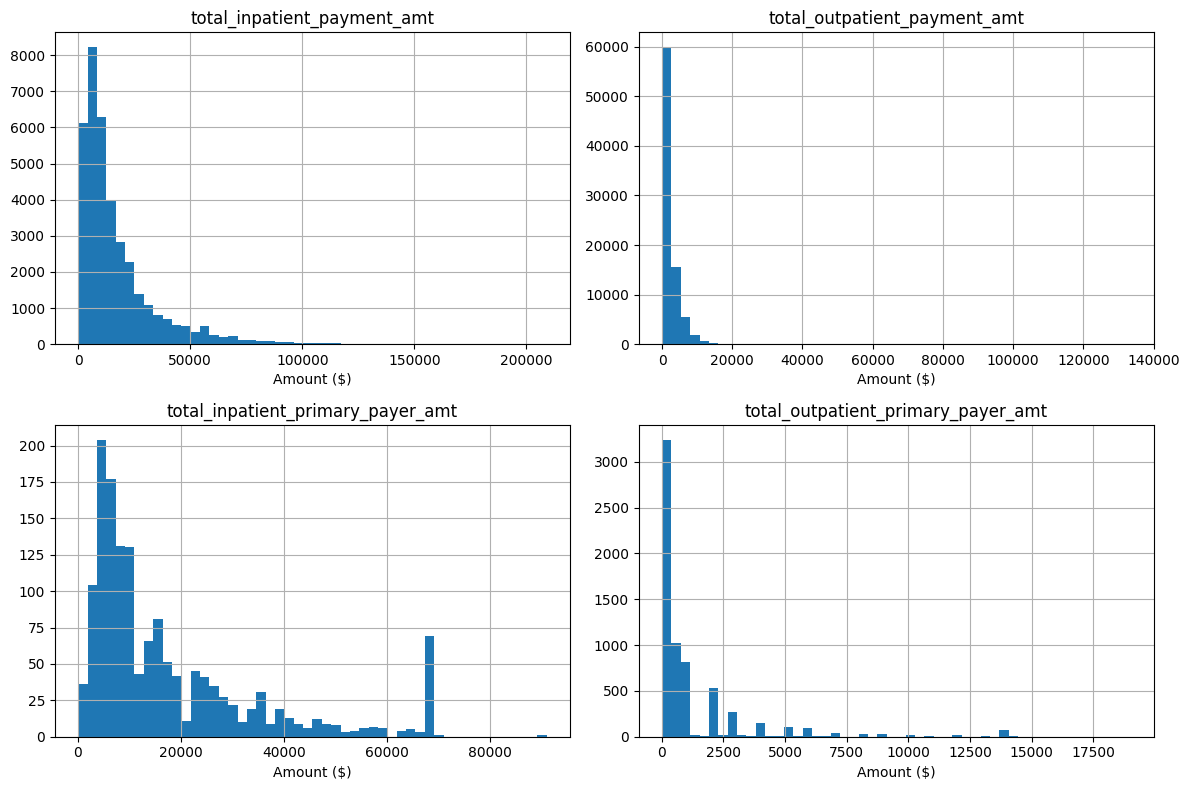

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), financial_cols):
    df[df[col] > 0][col].hist(bins=50, ax=ax)  # nonzero only, so the shape isn't hidden by the mass of zeros
    ax.set_title(col)
    ax.set_xlabel("Amount ($)")

plt.tight_layout()
plt.show()

In [10]:
print(df["total_inpatient_days"].describe())

print("\n--- Beneficiaries with unusually high inpatient days ---")
print(df[df["total_inpatient_days"] > 100][["DESYNPUF_ID", "total_inpatient_claims", "total_inpatient_days", "total_inpatient_payment_amt"]].sort_values("total_inpatient_days", ascending=False).head(10))

count    116352.000000
mean          3.200693
std           8.368789
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max         202.000000
Name: total_inpatient_days, dtype: float64

--- Beneficiaries with unusually high inpatient days ---
             DESYNPUF_ID  total_inpatient_claims  total_inpatient_days  \
79426   AEE2353E80207F0C                     9.0                 202.0   
1439    0307F3BF85515EBA                     7.0                 179.0   
106073  E98BAEB928033BC0                     8.0                 171.0   
104836  E6B1D41E11ECCC45                     6.0                 160.0   
85221   BBB330A1FD3DCE3A                     6.0                 158.0   
36073   4EBB6AF09B30580A                     7.0                 150.0   
26852   3A9D94388C426924                    12.0                 144.0   
113198  F8F72B475A3381DC                     8.0                 142.0   
59131   817FCE82A9FDD269                     8.0 

In [11]:
chronic_cols = [c for c in df.columns if c.startswith("SP_") and c not in ["SP_STATE_CODE"]]
condition_prevalence = df[chronic_cols].mean().sort_values(ascending=False) * 100
condition_prevalence.round(1)

SP_ISCHMCHT    42.1
SP_DIABETES    37.9
SP_CHF         28.5
SP_DEPRESSN    21.3
SP_ALZHDMTA    19.3
SP_OSTEOPRS    17.3
SP_CHRNKIDN    16.1
SP_RA_OA       15.4
SP_COPD        13.5
SP_CNCR         6.4
SP_STRKETIA     4.5
dtype: float64